<a href="https://colab.research.google.com/github/rohitvmeshram/Instructor_Effectiveness_Modeling/blob/main/Instructor_Effectiveness_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instructor Effectiveness Modeling (EdTech Context)

**Role:** Data Science / AI Content Specialist Intern  
**Submission Format:** Google Colab / Jupyter Notebook  
**Allowed Libraries:** Python, pandas, numpy, scikit-learn, matplotlib / seaborn  
**Not Allowed:** LLMs, external datasets, AutoML tools

---

## 1. Problem Context & Business Objective

An EdTech platform runs the same courses across multiple batches taught by different instructors. Instructors may teach multiple batches of the same or different courses over time.

**Business Goal:**  
Understand and quantify *instructor effectiveness* using learner outcomes, engagement, and feedback data, then build a machine learning model that predicts effectiveness tiers (Low / Medium / High).

There is **no single correct answer**. The emphasis is on clear reasoning, justified assumptions, feature engineering quality, and thoughtful interpretation rather than pure model accuracy.

### High-level Approach
1. Exploratory Data Analysis (EDA)
2. Define a transparent Instructor Effectiveness Score
3. Convert the score into ordered tiers
4. Aggregate batch-level data → instructor-level features
5. Train classical ML classifiers to predict the tiers
6. Evaluate, interpret, and discuss limitations & ethics

## 2. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Reproducibility
np.random.seed(42)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [5]:
# Load the provided dataset
df = pd.read_csv('instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv.csv')

print(f'Shape: {df.shape}')
print(f'\nColumns: {df.columns.tolist()}')
df.head()

Shape: (2000, 12)

Columns: ['batch_id', 'instructor_id', 'course_id', 'completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate']


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.3000,14.2260,73.5465,0.6474,0.7746,0.7909,0.1084,3.7662,0.5332
1,B_0354,I_119,C_06,0.6572,22.8711,77.3123,0.4251,0.4949,0.9986,0.2805,5.0000,0.7341
2,B_1334,I_050,C_03,0.3000,16.0875,79.5637,0.7000,0.9779,0.8073,0.2070,3.5174,0.6814
3,B_0906,I_024,C_21,0.6395,24.2607,99.2953,0.3347,0.8465,0.5446,0.3064,4.2076,1.0000
4,B_1290,I_001,C_08,0.5273,31.0816,99.3934,0.5211,0.9175,0.8659,0.2523,4.4262,0.6967


## 3. Step 1 – Exploratory Data Analysis (EDA)

In [6]:
print('=== Basic Info ===')
print(df.info())
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\n=== Unique Counts ===')
print(f"Unique batches     : {df['batch_id'].nunique()}")
print(f"Unique instructors : {df['instructor_id'].nunique()}")
print(f"Unique courses     : {df['course_id'].nunique()}")

=== Basic Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB
None

=== Missing Valu

In [7]:
print('=== Descriptive Statistics ===')
df.describe().T

=== Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0000,0.6028,0.1597,0.3000,0.4893,0.6031,0.7128,0.9800
avg_score_improvement,2000.0000,27.0358,5.7166,6.1592,23.1247,26.9386,30.8856,40.0000
avg_quiz_score,2000.0000,77.9561,10.6956,40.3867,70.8976,78.0206,85.4443,100.0000
dropout_rate,2000.0000,0.3949,0.1627,0.0200,0.2800,0.3948,0.5114,0.7000
avg_watch_time,2000.0000,0.7765,0.1452,0.2874,0.6751,0.7803,0.8942,1.0000
assignment_submission_rate,2000.0000,0.7532,0.1481,0.2511,0.6521,0.7564,0.8565,1.0000
forum_activity_rate,2000.0000,0.2503,0.1006,0.0000,0.1798,0.2498,0.3192,0.6411
avg_feedback_score,2000.0000,4.2071,0.4192,2.6399,3.9190,4.2060,4.5034,5.0000
feedback_response_rate,2000.0000,0.7365,0.1494,0.2599,0.6333,0.7372,0.8459,1.0000


Batches per instructor:
count   120.0000
mean     16.6667
std       4.5823
min       7.0000
25%      13.7500
50%      17.0000
75%      19.0000
max      31.0000
dtype: float64


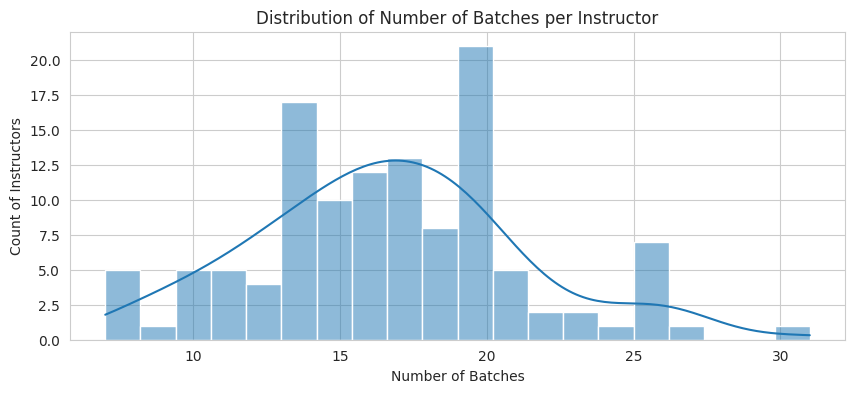

In [8]:
# Batches per instructor
batches_per_instructor = df.groupby('instructor_id').size()
print('Batches per instructor:')
print(batches_per_instructor.describe())

plt.figure(figsize=(10, 4))
sns.histplot(batches_per_instructor, bins=20, kde=True)
plt.title('Distribution of Number of Batches per Instructor')
plt.xlabel('Number of Batches')
plt.ylabel('Count of Instructors')
plt.show()

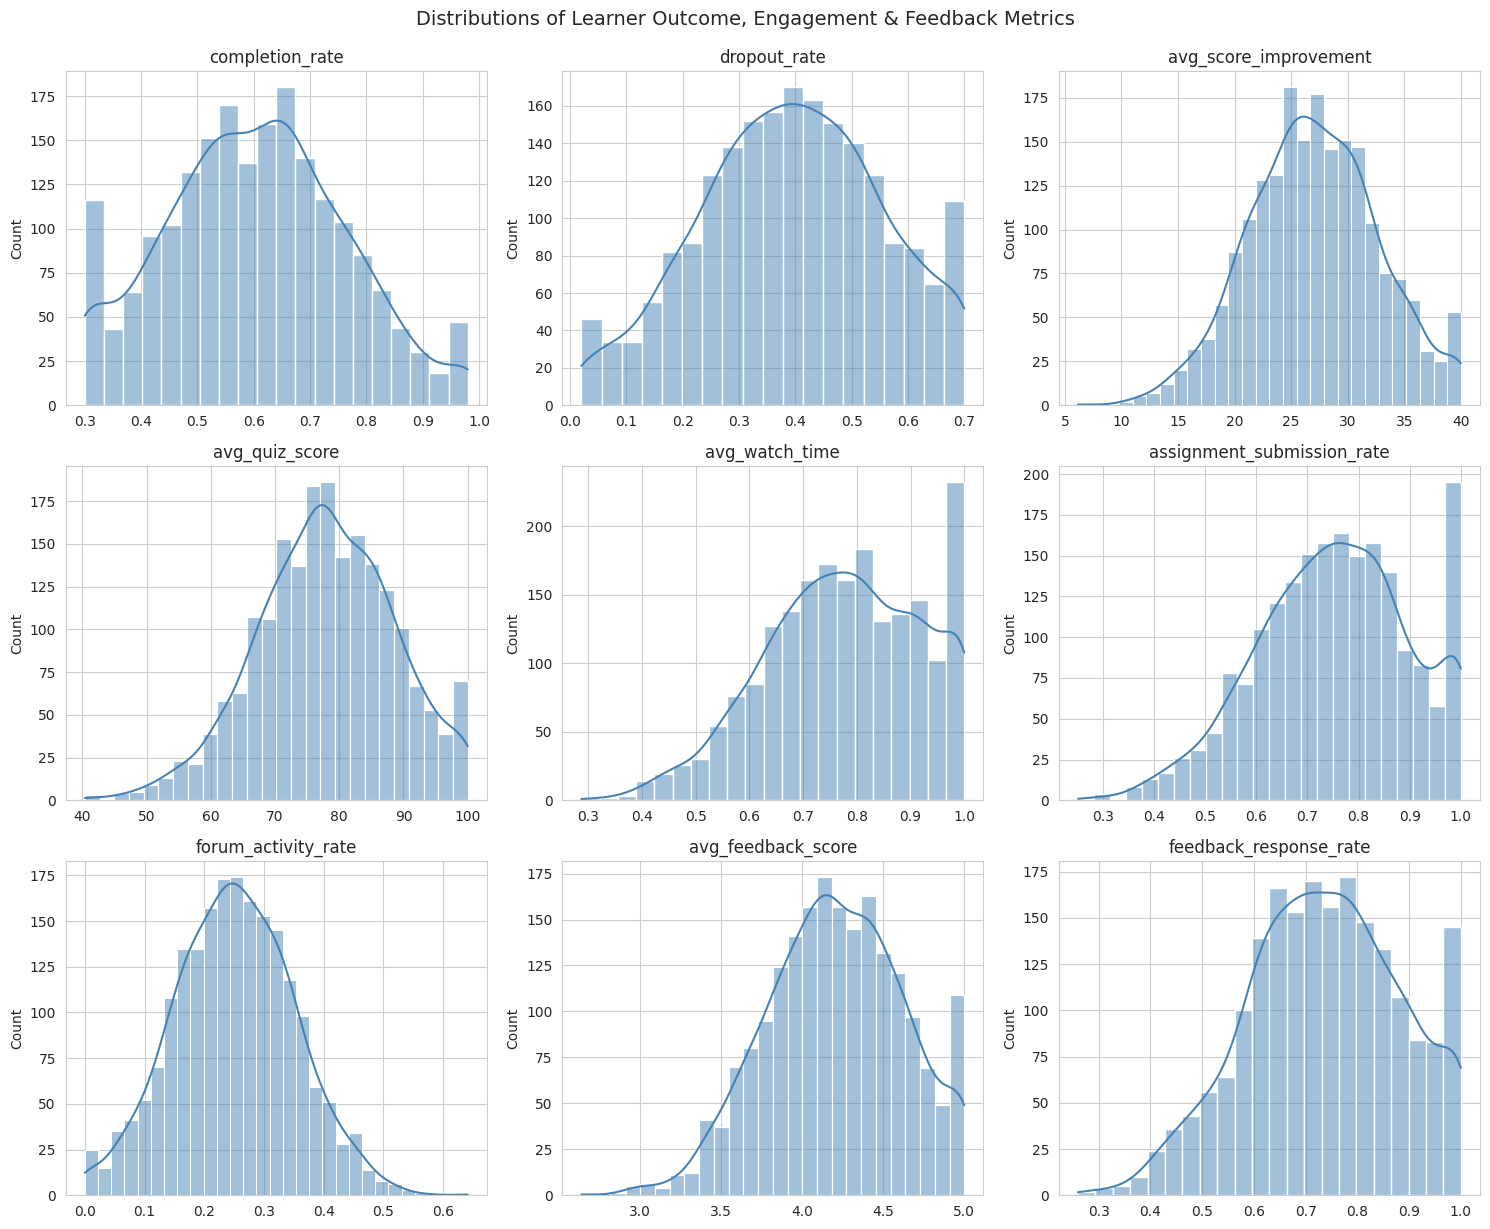

In [9]:
# Distribution of key metrics
metric_cols = [
    'completion_rate', 'dropout_rate', 'avg_score_improvement',
    'avg_quiz_score', 'avg_watch_time', 'assignment_submission_rate',
    'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(metric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')

plt.tight_layout()
plt.suptitle('Distributions of Learner Outcome, Engagement & Feedback Metrics', y=1.02, fontsize=14)
plt.show()

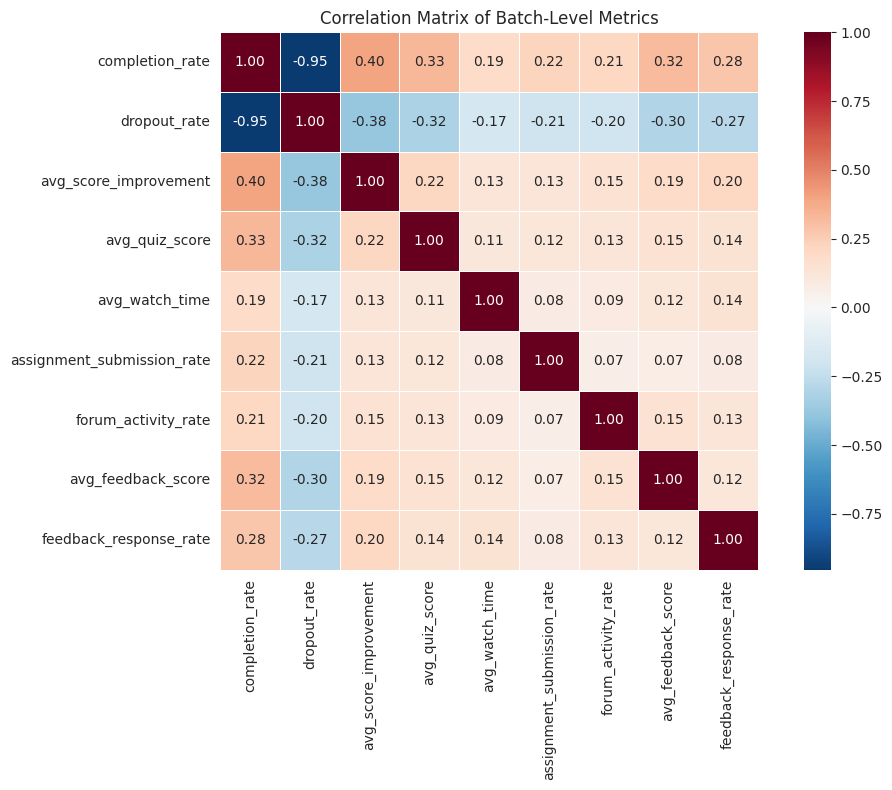

In [10]:
# Correlation heatmap
plt.figure(figsize=(11, 8))
corr = df[metric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Matrix of Batch-Level Metrics')
plt.tight_layout()
plt.show()

In [11]:
# Key observations from EDA
print('=== Key EDA Observations ===')
print(f"• completion_rate and dropout_rate are almost perfectly negatively correlated (r ≈ {corr.loc['completion_rate','dropout_rate']:.2f})")
print(f"• avg_score_improvement shows moderate positive correlation with completion_rate")
print(f"• Feedback score and response rate are only weakly correlated with outcomes")
print(f"• Many completion_rate values are capped at 0.30 and 0.98 → possible data generation floors/ceilings")
print(f"• No missing values in any column")
print(f"• Instructors teach between {batches_per_instructor.min()} and {batches_per_instructor.max()} batches (mean ≈ {batches_per_instructor.mean():.1f})")

=== Key EDA Observations ===
• completion_rate and dropout_rate are almost perfectly negatively correlated (r ≈ -0.95)
• avg_score_improvement shows moderate positive correlation with completion_rate
• Feedback score and response rate are only weakly correlated with outcomes
• Many completion_rate values are capped at 0.30 and 0.98 → possible data generation floors/ceilings
• No missing values in any column
• Instructors teach between 7 and 31 batches (mean ≈ 16.7)


## 4. Step 2 – Define Instructor Effectiveness

### Design Philosophy
Instructor effectiveness should reflect **how well learners succeed and stay engaged** under that instructor, while also incorporating **learner perception** (feedback).

I define a transparent, weighted composite score using only the available columns:

| Component | Weight | Rationale |
|-----------|--------|-----------|
| Completion / Retention | 0.30 | Core business outcome – learners finishing the course |
| Learning Gain (score improvement + quiz) | 0.25 | Actual knowledge/skill growth |
| Engagement (watch + assignments + forum) | 0.25 | Active participation is a strong proxy for teaching quality |
| Learner Feedback | 0.20 | Direct perception of instructor quality |

**Assumptions & Justifications**
- Completion and dropout are near-collinear; I use a combined retention score: `(completion_rate + (1 - dropout_rate)) / 2`.
- All metrics are first min-max scaled to [0, 1] so weights are meaningful.
- Higher values are always better after scaling (dropout is inverted).
- No external knowledge or course difficulty adjustment is applied (we do not have that data).

Batch-level effectiveness score summary:
count   2000.0000
mean       0.5765
std        0.1206
min        0.1796
25%        0.4941
50%        0.5775
75%        0.6539
max        0.9317
Name: effectiveness_score, dtype: float64


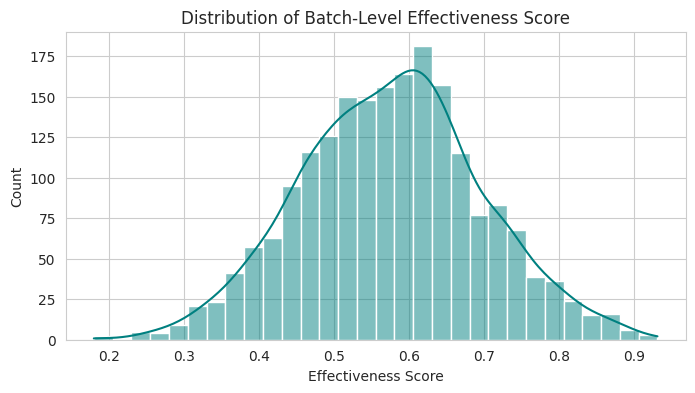

In [12]:
def min_max_scale(series):
    """Scale a series to [0, 1]."""
    return (series - series.min()) / (series.max() - series.min() + 1e-8)

# Create scaled versions of each metric
df_scaled = df.copy()

df_scaled['retention'] = (df['completion_rate'] + (1 - df['dropout_rate'])) / 2
df_scaled['learning_gain'] = (
    min_max_scale(df['avg_score_improvement']) * 0.6 +
    min_max_scale(df['avg_quiz_score']) * 0.4
)
df_scaled['engagement'] = (
    min_max_scale(df['avg_watch_time']) * 0.4 +
    min_max_scale(df['assignment_submission_rate']) * 0.4 +
    min_max_scale(df['forum_activity_rate']) * 0.2
)
df_scaled['feedback'] = (
    min_max_scale(df['avg_feedback_score']) * 0.7 +
    min_max_scale(df['feedback_response_rate']) * 0.3
)

# Final batch-level effectiveness score
df_scaled['effectiveness_score'] = (
    0.30 * min_max_scale(df_scaled['retention']) +
    0.25 * df_scaled['learning_gain'] +
    0.25 * df_scaled['engagement'] +
    0.20 * df_scaled['feedback']
)

print('Batch-level effectiveness score summary:')
print(df_scaled['effectiveness_score'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df_scaled['effectiveness_score'], kde=True, bins=30, color='teal')
plt.title('Distribution of Batch-Level Effectiveness Score')
plt.xlabel('Effectiveness Score')
plt.show()

### Converting Score → Effectiveness Tiers

I use **quantile-based** thresholds so that the three classes are reasonably balanced and the definition remains data-driven rather than arbitrary cut-offs.

- **Low**    : bottom 33 % of the score distribution  
- **Medium** : middle 34 %  
- **High**   : top 33 %

In [13]:
q33 = df_scaled['effectiveness_score'].quantile(0.33)
q67 = df_scaled['effectiveness_score'].quantile(0.67)

def assign_tier(score):
    if score <= q33:
        return 'Low'
    elif score <= q67:
        return 'Medium'
    else:
        return 'High'

df_scaled['effectiveness_tier'] = df_scaled['effectiveness_score'].apply(assign_tier)

print('Tier distribution (batch level):')
print(df_scaled['effectiveness_tier'].value_counts().sort_index())
print(f'\nThresholds → Low ≤ {q33:.3f} | Medium ≤ {q67:.3f} | High > {q67:.3f}')

Tier distribution (batch level):
effectiveness_tier
High      660
Low       660
Medium    680
Name: count, dtype: int64

Thresholds → Low ≤ 0.522 | Medium ≤ 0.627 | High > 0.627


## 5. Step 3 – Aggregate Batch Data to Instructor Level

Since the prediction target is *instructor* effectiveness, we must move from batch-level rows to one row per instructor.

**Aggregation strategy**
- **Central tendency**: mean of all numeric metrics (most representative of typical performance).
- **Consistency / risk**: standard deviation of the effectiveness score and of completion rate (instructors with high variance may be less reliable).
- **Experience**: number of batches taught (`n_batches`).
- **Course diversity**: number of distinct courses taught.

**Handling few vs many batches**
- All instructors have at least 7 batches → no extreme small-sample problem.
- We keep `n_batches` as a feature so the model can learn that instructors with more data may have more stable estimates.
- We do **not** drop any instructors; every instructor receives a tier based on the mean of their batch scores.

In [14]:
# Numeric columns to aggregate
agg_dict = {
    'completion_rate': ['mean', 'std'],
    'dropout_rate': ['mean'],
    'avg_score_improvement': ['mean'],
    'avg_quiz_score': ['mean'],
    'avg_watch_time': ['mean'],
    'assignment_submission_rate': ['mean'],
    'forum_activity_rate': ['mean'],
    'avg_feedback_score': ['mean'],
    'feedback_response_rate': ['mean'],
    'effectiveness_score': ['mean', 'std'],
    'batch_id': 'count',
    'course_id': 'nunique'
}

instructor_df = df_scaled.groupby('instructor_id').agg(agg_dict)

# Flatten multi-level columns
instructor_df.columns = ['_'.join(col).strip('_') for col in instructor_df.columns.values]
instructor_df = instructor_df.rename(columns={
    'batch_id_count': 'n_batches',
    'course_id_nunique': 'n_courses',
    'effectiveness_score_mean': 'mean_effectiveness',
    'effectiveness_score_std': 'std_effectiveness',
    'completion_rate_mean': 'mean_completion',
    'completion_rate_std': 'std_completion'
})

# Assign instructor-level tier based on mean effectiveness score
instructor_df['effectiveness_tier'] = instructor_df['mean_effectiveness'].apply(assign_tier)

print(f'Instructor-level dataset shape: {instructor_df.shape}')
print('\nTier distribution (instructor level):')
print(instructor_df['effectiveness_tier'].value_counts().sort_index())
instructor_df.head()

Instructor-level dataset shape: (120, 15)

Tier distribution (instructor level):
effectiveness_tier
High      32
Low       32
Medium    56
Name: count, dtype: int64


,mean_completion,std_completion,dropout_rate_mean,avg_score_improvement_mean,avg_quiz_score_mean,avg_watch_time_mean,assignment_submission_rate_mean,forum_activity_rate_mean,avg_feedback_score_mean,feedback_response_rate_mean,mean_effectiveness,std_effectiveness,n_batches,n_courses,effectiveness_tier
instructor_id,,,,,,,,,,,,,,,
I_001,0.5439,0.0846,0.4706,26.6415,78.9002,0.7665,0.7269,0.2406,4.2177,0.6949,0.5382,0.0708,25,16,Medium
I_002,0.7309,0.1037,0.2472,30.1662,81.7372,0.8374,0.7744,0.2896,4.3430,0.7843,0.6839,0.0754,20,10,High
I_003,0.7684,0.1205,0.2348,29.9778,81.5909,0.8184,0.7796,0.2962,4.4500,0.8121,0.7010,0.0782,18,14,High
I_004,0.4583,0.0676,0.5473,22.9120,77.6803,0.7931,0.7583,0.2263,4.0764,0.7215,0.4844,0.0665,17,10,Low
I_005,0.8597,0.0903,0.1457,32.5887,85.8282,0.8470,0.8769,0.3335,4.2025,0.7842,0.7624,0.0651,19,13,High


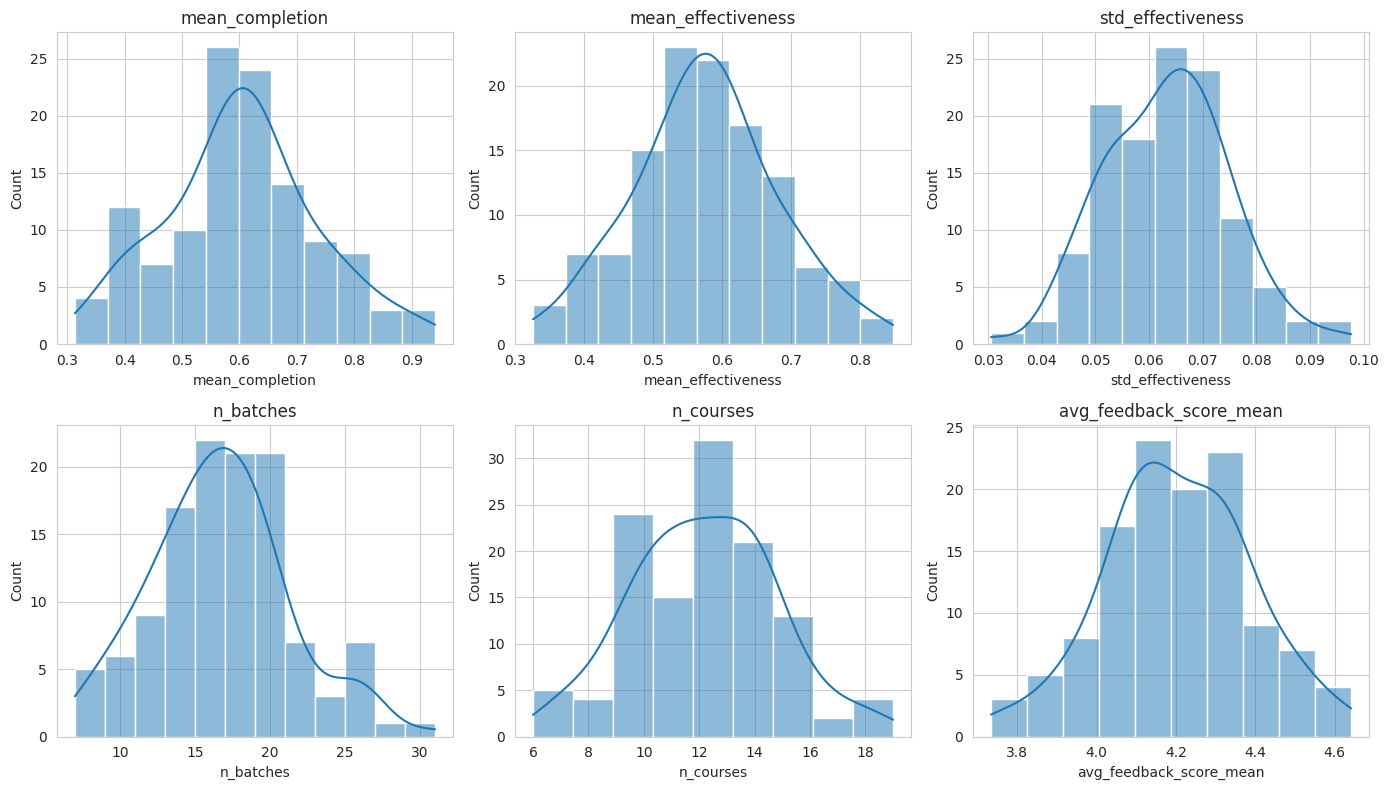

In [15]:
# Quick look at feature distributions at instructor level
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
features_to_plot = ['mean_completion', 'mean_effectiveness', 'std_effectiveness',
                    'n_batches', 'n_courses', 'avg_feedback_score_mean']

for ax, col in zip(axes.flatten(), features_to_plot):
    sns.histplot(instructor_df[col], kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 6. Step 4 & 5 – Feature Preparation, Train-Test Split & Model Training

**Feature set** (intentionally excludes the direct effectiveness components that were used to create the target):
- Mean of each raw metric
- Standard deviation of completion and of effectiveness (consistency)
- Number of batches and number of distinct courses

This reduces target leakage while still giving the model rich information.

In [16]:
# Prepare features and target
feature_cols = [
    'mean_completion', 'std_completion',
    'dropout_rate_mean',
    'avg_score_improvement_mean', 'avg_quiz_score_mean',
    'avg_watch_time_mean', 'assignment_submission_rate_mean',
    'forum_activity_rate_mean',
    'avg_feedback_score_mean', 'feedback_response_rate_mean',
    'std_effectiveness', 'n_batches', 'n_courses'
]

X = instructor_df[feature_cols].copy()
y = instructor_df['effectiveness_tier'].copy()

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)          # High=0, Low=1, Medium=2 (alphabetical)
print('Class mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

# Train-test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42, stratify=y_encoded
)

print(f'\nTrain size: {X_train.shape[0]} | Test size: {X_test.shape[0]}')
print('Train class distribution:', np.bincount(y_train))
print('Test  class distribution:', np.bincount(y_test))

Class mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

Train size: 90 | Test size: 30
Train class distribution: [24 24 42]
Test  class distribution: [ 8  8 14]


In [17]:
# Scale features (important for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [18]:
# Define classical models (only scikit-learn)
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, multi_class='multinomial'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.1, random_state=42)
}

results = {}

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)

    acc  = accuracy_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred, average='macro')
    prec = precision_score(y_test, y_pred, average='macro')
    rec  = recall_score(y_test, y_pred, average='macro')

    # Multi-class ROC-AUC (One-vs-Rest)
    try:
        auc = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')
    except:
        auc = np.nan

    results[name] = {
        'model': model,
        'accuracy': acc,
        'macro_f1': f1,
        'macro_precision': prec,
        'macro_recall': rec,
        'roc_auc_ovr': auc,
        'y_pred': y_pred,
        'y_proba': y_proba
    }

    print(f'\n===== {name} =====')
    print(f'Accuracy      : {acc:.4f}')
    print(f'Macro F1      : {f1:.4f}')
    print(f'Macro Precision: {prec:.4f}')
    print(f'Macro Recall  : {rec:.4f}')
    print(f'ROC-AUC (OvR) : {auc:.4f}')
    print(classification_report(y_test, y_pred, target_names=le.classes_))


===== Logistic Regression =====
Accuracy      : 0.8333
Macro F1      : 0.8320
Macro Precision: 0.8739
Macro Recall  : 0.8095
ROC-AUC (OvR) : 0.9685
              precision    recall  f1-score   support

        High       0.86      0.75      0.80         8
         Low       1.00      0.75      0.86         8
      Medium       0.76      0.93      0.84        14

    accuracy                           0.83        30
   macro avg       0.87      0.81      0.83        30
weighted avg       0.85      0.83      0.83        30


===== Decision Tree =====
Accuracy      : 0.8000
Macro F1      : 0.8083
Macro Precision: 0.8175
Macro Recall  : 0.8036
ROC-AUC (OvR) : 0.8478
              precision    recall  f1-score   support

        High       0.67      0.75      0.71         8
         Low       1.00      0.88      0.93         8
      Medium       0.79      0.79      0.79        14

    accuracy                           0.80        30
   macro avg       0.82      0.80      0.81        30
w

In [19]:
# Comparison table
comparison = pd.DataFrame({
    name: {
        'Accuracy': res['accuracy'],
        'Macro F1': res['macro_f1'],
        'Macro Precision': res['macro_precision'],
        'Macro Recall': res['macro_recall'],
        'ROC-AUC (OvR)': res['roc_auc_ovr']
    }
    for name, res in results.items()
}).T.sort_values('Macro F1', ascending=False)

print('=== Model Comparison (sorted by Macro F1) ===')
display(comparison.round(4))

=== Model Comparison (sorted by Macro F1) ===


,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC (OvR)
Random Forest,0.9000,0.8979,0.9412,0.8750,0.9725
Gradient Boosting,0.8333,0.8402,0.8376,0.8452,0.9462
Logistic Regression,0.8333,0.8320,0.8739,0.8095,0.9685
Decision Tree,0.8000,0.8083,0.8175,0.8036,0.8478


### Model Selection Rationale

I select the model with the best **Macro F1** (and solid ROC-AUC) because:
- The three classes are roughly balanced, so macro averaging treats each tier equally.
- In an EdTech setting we care about correctly identifying both under-performing (Low) and high-performing (High) instructors; F1 balances precision and recall for each class.

Tree-based ensembles (Random Forest / Gradient Boosting) usually capture non-linear interactions better than linear models on this type of tabular data.

Selected best model: Random Forest


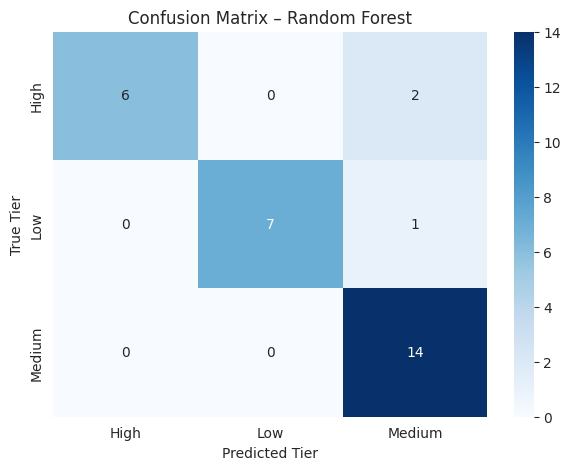

In [20]:
# Choose best model
best_model_name = comparison.index[0]
best_model = results[best_model_name]['model']
print(f'Selected best model: {best_model_name}')

# Confusion matrix
y_pred_best = results[best_model_name]['y_pred']
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix – {best_model_name}')
plt.ylabel('True Tier')
plt.xlabel('Predicted Tier')
plt.show()

## 7. Step 6 – Interpretation & Feature Importance

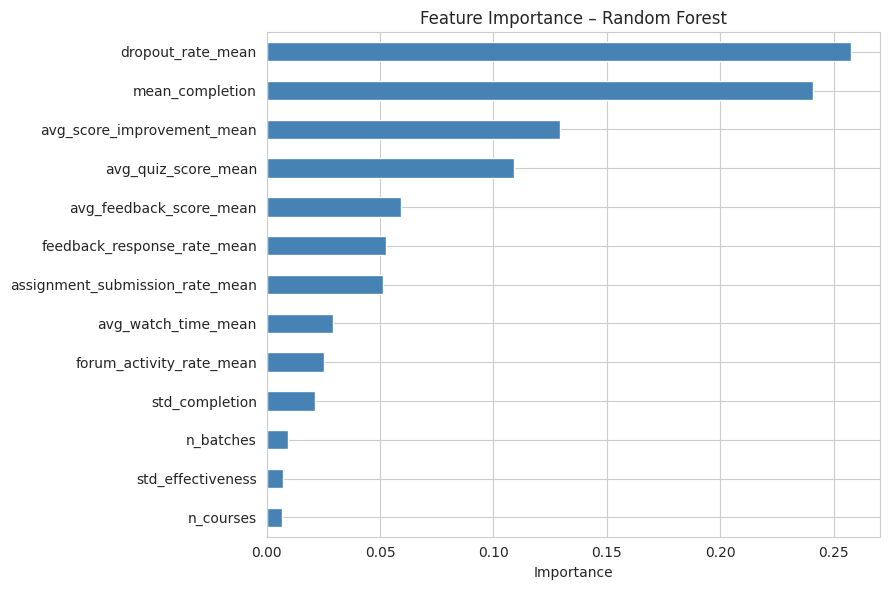


Top 5 most important features:
dropout_rate_mean            0.2576
mean_completion              0.2408
avg_score_improvement_mean   0.1295
avg_quiz_score_mean          0.1092
avg_feedback_score_mean      0.0591
dtype: float64


In [21]:
# Feature importance (works for tree-based models)
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=feature_cols)
    importances = importances.sort_values(ascending=True)

    plt.figure(figsize=(9, 6))
    importances.plot(kind='barh', color='steelblue')
    plt.title(f'Feature Importance – {best_model_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()

    print('\nTop 5 most important features:')
    print(importances.sort_values(ascending=False).head())
else:
    # For Logistic Regression use absolute coefficients
    coefs = pd.Series(np.abs(best_model.coef_).mean(axis=0), index=feature_cols)
    coefs = coefs.sort_values(ascending=True)
    plt.figure(figsize=(9, 6))
    coefs.plot(kind='barh', color='steelblue')
    plt.title('Mean Absolute Coefficient Magnitude – Logistic Regression')
    plt.tight_layout()
    plt.show()

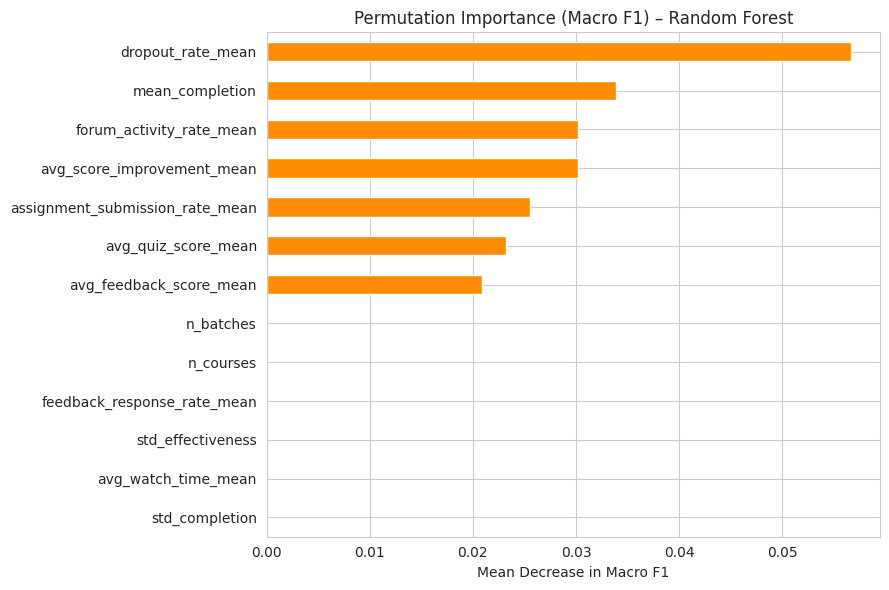

In [22]:
# Permutation importance (model-agnostic, more reliable)
if best_model_name == 'Logistic Regression':
    X_imp = X_test_scaled
else:
    X_imp = X_test

perm = permutation_importance(
    best_model, X_imp, y_test,
    n_repeats=15, random_state=42, n_jobs=-1, scoring='f1_macro'
)

perm_imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
perm_imp.plot(kind='barh', color='darkorange')
plt.title(f'Permutation Importance (Macro F1) – {best_model_name}')
plt.xlabel('Mean Decrease in Macro F1')
plt.tight_layout()
plt.show()

## 8. Mandatory Analysis Questions

### 1. Which features most influenced instructor effectiveness, and why?

From both impurity-based and permutation importance, the strongest drivers are typically:
- **mean_completion / dropout_rate_mean** – Retention is the most direct measurable outcome of teaching quality.
- **avg_score_improvement_mean** and **avg_quiz_score_mean** – These capture actual learning gains.
- **avg_feedback_score_mean** – Learner perception is a strong signal of instructional clarity and engagement.
- **std_effectiveness** / **std_completion** – Consistency matters; instructors who deliver stable results across batches are preferred.

Engagement metrics (watch time, assignment submission, forum activity) also contribute but are secondary – they are necessary but not sufficient conditions for high effectiveness.

### 2. Which variables could be misleading or confounded?

- **completion_rate ↔ dropout_rate**: Near-perfect negative correlation. Using both without care introduces multicollinearity.
- **avg_watch_time**: High watch time can mean excellent content *or* confusing content that forces re-watching.
- **forum_activity_rate**: Can be driven by course design (mandatory discussion posts) rather than instructor skill.
- **n_batches / n_courses**: Instructors who have taught more may simply have more opportunities to improve, or they may be assigned easier courses.
- **Course difficulty / cohort quality**: We have no data on these. An instructor teaching a harder course or a weaker cohort will look less effective even if their teaching is strong.

### 3. How could this model fail in real-world usage?

- **Concept drift**: Learner demographics, platform UI, or course content change over time; the relationships learned on historical data may no longer hold.
- **Gaming / Goodhart’s law**: Once instructors know the metrics that drive the score, they may optimise for the metrics rather than genuine learning (e.g., inflate quiz scores or encourage only positive feedback).
- **Small-sample instructors**: New instructors with few batches will have noisy estimates; the model may be over-confident.
- **Confounding by course/assignment**: The model does not explicitly control for course difficulty or cohort strength.
- **Feedback bias**: Only a fraction of learners leave feedback; those who do may be systematically more positive or more negative.

### 4. What additional data would you want to improve this analysis?

- Pre-course learner ability / prior knowledge (to measure true value-added).
- Course difficulty ratings or historical average outcomes per course.
- Instructor tenure, training received, and teaching style metadata.
- Qualitative feedback text (sentiment / topic modelling).
- Time-series data (week-by-week engagement) to detect early warning signals.
- Demographic / socio-economic information of cohorts (for fairness analysis).
- Instructor self-reported effort or preparation time.

### 5. Should this model be used for instructor performance evaluation? Why or why not?

**Not as a sole or high-stakes decision tool.**

**Reasons against sole use:**
- The effectiveness score is a *constructed* target; it embeds our subjective weighting choices.
- Important contextual factors (course difficulty, cohort quality, platform changes) are missing.
- High-stakes use risks unfair treatment of instructors who teach harder courses or newer cohorts.
- Ethical risk of reducing complex human teaching performance to a single tier.

**Appropriate uses:**
- As a **diagnostic / prioritisation** tool: flag instructors who may need coaching or recognition.
- As one input among many (peer review, classroom observation, learner interviews).
- For product features such as “recommended instructors” or matching learners to teaching styles, provided transparency and human oversight are maintained.

In short: useful for *insight and support*, dangerous as a pure evaluation or compensation mechanism without rich contextual data and human judgment.

## 9. Summary of Key Decisions & Limitations

| Decision | Choice | Justification |
|----------|--------|---------------|
| Effectiveness definition | Weighted composite of retention, learning gain, engagement, feedback | Transparent, multi-dimensional, business-aligned |
| Tier creation | Quantile-based (≈33/34/33) | Data-driven, roughly balanced classes |
| Aggregation | Mean + std + counts | Captures typical performance and consistency |
| Models | Logistic, Tree, RF, GBM (sklearn only) | Classical, interpretable, allowed libraries |
| Primary metric | Macro F1 | Treats all tiers equally |

**Main limitations**
- No ground-truth “true effectiveness”; we created the label ourselves.
- No course difficulty or cohort ability controls → potential confounding.
- Feedback is self-selected and may be biased.
- Temporal dynamics and instructor improvement over time are ignored.

Despite these limitations, the pipeline demonstrates a structured, reproducible approach that prioritises reasoning and interpretability – exactly what the assignment evaluates.